# 03b · Survival analysis: diagnostics, benchmarks, calibration and backtest
**Owner:** Pricing & Availability Lead · **Needs:** steps 1b–4; `lifelines`, `scikit-survival` · Production code: `src/homefit/survival.py`

Notebook 03 built the availability model. This notebook tests it the way a survival analyst would:

| § | Question | Method |
|---|---|---|
| 1 | Does proportional hazards hold, and is stratifying on block age the right fix? | Log–log Kaplan–Meier curves |
| 2 | What does the final model say, with honest uncertainty? | Stratified Cox, robust (block-clustered) vs naive standard errors |
| 3 | Does the final model pass the PH assumption? | Schoenfeld residual tests and plots |
| 4 | Are covariates in the right functional form? Does the model fit overall? | Martingale residuals; Cox–Snell residuals |
| 5 | Is Cox the right choice? | Kaplan–Meier vs Cox vs Weibull AFT vs log-normal AFT vs random survival forest: C-index (bootstrap CI), integrated Brier score, calibration |
| 6 | Do the design choices bias results? | Left-truncation sensitivity; market-activity covariate |
| 7 | Does the production availability estimate hold up over time? | Rolling backtest at 7 dates, 2019–2025; prior-weight sensitivity |
| 8 | How uncertain is each profile's wait? | Poisson–gamma intervals and their coverage |

In [1]:
import sys, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import config as C
from homefit import common as K, survival as S, profiles as PR
from lifelines import CoxPHFitter, KaplanMeierFitter, WeibullAFTFitter, LogNormalAFTFitter, NelsonAalenFitter
from lifelines.statistics import proportional_hazard_test
from lifelines.utils import concordance_index
from scipy.stats import spearmanr, nbinom, gamma, poisson
BLUE, GREY, ORANGE, GREEN = "#2a78d6", "#9a9a95", "#eb6834", "#1baf7a"
plt.rcParams.update({"figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#9a9a95", "lines.linewidth": 1.8, "legend.frameon": False, "font.size": 10})
AS_OF = K.latest_complete_month()
t0 = time.time()
F = S.spells(AS_OF)
Mf = S.model_frame(F)
Mf["duration"], Mf["event"], Mf["address"] = F["duration"].to_numpy(), F["event"].to_numpy(), F["address"].to_numpy()
COV = [c for c in Mf.columns if c not in ("duration", "event", "age_band", "address")]
print(f"As of {AS_OF}: {len(F):,} spells, {F['event'].mean():.1%} end in a sale · covariates: {COV} · {time.time() - t0:.0f}s")

As of 2026-09: 244,672 spells, 92.6% end in a sale · covariates: ['flat_type_3 ROOM', 'flat_type_4 ROOM', 'flat_type_5 ROOM', 'flat_type_EXECUTIVE', 'region_EAST', 'region_NORTH', 'region_NORTH-EAST', 'region_WEST', 'log_dist_mrt', 'log_dist_hawker', 'log_dist_park', 'log_dist_supermarket', 'log_units', 'max_floor_lvl', 'from_2020', 'n_primary_1km'] · 2s


## 1 · Proportional hazards, visually: log–log Kaplan–Meier curves
Under proportional hazards, log(−log S(t)) curves for groups are parallel. Crossing or converging curves mean the effect changes over time.

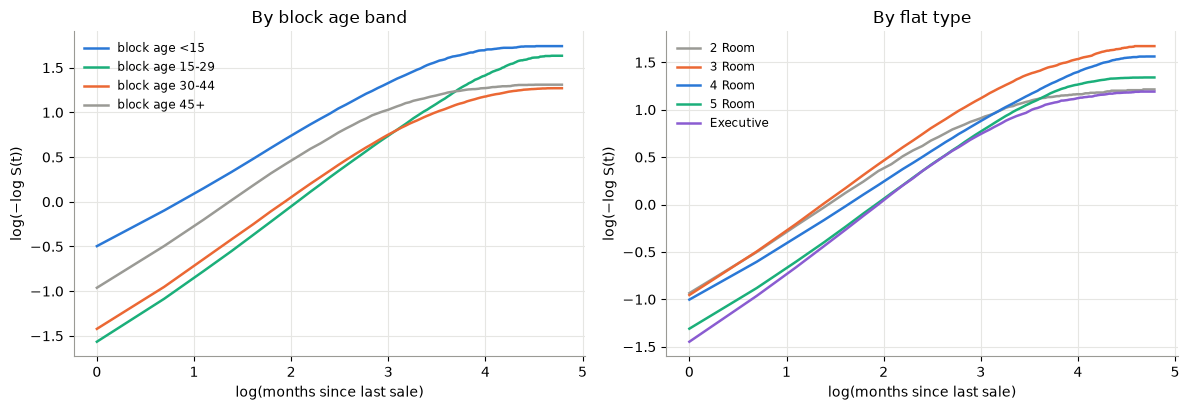

block age <15   :  70,982 spells · median wait 2.0 months · still waiting at 24 months 1.6%
block age 15-29 :  67,914 spells · median wait 6.0 months · still waiting at 24 months 9.2%
block age 30-44 :  84,708 spells · median wait 5.0 months · still waiting at 24 months 9.6%
block age 45+   :  21,068 spells · median wait 3.0 months · still waiting at 24 months 4.9%


In [2]:
times = np.arange(1, 121)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for g, c in zip(S.AGE_LABELS, [BLUE, GREEN, ORANGE, GREY]):
    m = Mf["age_band"] == g
    km = KaplanMeierFitter().fit(Mf.loc[m, "duration"], Mf.loc[m, "event"])
    s = km.survival_function_at_times(times).clip(1e-6, 1 - 1e-6)
    ax[0].plot(np.log(times), np.log(-np.log(s)), color=c, label=f"block age {g}")
for t, c in zip(K.TYPES, [GREY, ORANGE, BLUE, GREEN, "#8a5cd1"]):
    m = F["flat_type"] == t
    km = KaplanMeierFitter().fit(F.loc[m, "duration"], F.loc[m, "event"])
    s = km.survival_function_at_times(times).clip(1e-6, 1 - 1e-6)
    ax[1].plot(np.log(times), np.log(-np.log(s)), color=c, label=t.title())
for a, ttl in zip(ax, ["By block age band", "By flat type"]):
    a.set(xlabel="log(months since last sale)", ylabel="log(−log S(t))", title=ttl); a.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
for g in S.AGE_LABELS:
    m = Mf["age_band"] == g
    km = KaplanMeierFitter().fit(Mf.loc[m, "duration"], Mf.loc[m, "event"])
    print(f"block age {g:6s}: {m.sum():7,} spells · median wait {km.median_survival_time_:.1f} months · still waiting at 24 months {km.survival_function_at_times(24).iloc[0]:.1%}")

**Finding:** The log–log curves by block age are not parallel. The <15 band sits highest throughout (fastest turnover, median wait 2 months); the 15–29 and 30–44 bands cross at about 20 months; all bands flatten after about 4 years. A single proportional block-age term would be wrong, so block age is a stratum with its own baseline hazard (medians 2–6 months; 1.6–9.6% still waiting at 24 months).

The flat-type curves are close to parallel up to about 20 months and converge after that, a mild violation examined in §3.

## 2 · The final model: stratified Cox with block-clustered standard errors
Spells in the same block × flat type are repeated events (a gap-time, PWP-style set-up), so they are not independent. Robust (sandwich)
standard errors clustered by block allow for that. Comparing them with naive standard errors shows how much the clustering matters.

Fitted in 409s · concordance 0.647 · partial log-likelihood -2,275,048
                         HR  HR low  HR high      p  SE ratio (robust / naive)
covariate                                                                     
flat_type_3 ROOM      1.300   1.255    1.346  0.000                      1.362
flat_type_4 ROOM      1.155   1.118    1.194  0.000                      1.344
flat_type_5 ROOM      1.233   1.192    1.275  0.000                      1.314
flat_type_EXECUTIVE   1.441   1.387    1.496  0.000                      1.290
region_EAST           1.029   1.006    1.053  0.013                      1.389
region_NORTH          1.085   1.060    1.111  0.000                      1.411
region_NORTH-EAST     1.006   0.983    1.030  0.606                      1.460
region_WEST           0.977   0.954    1.000  0.054                      1.612
log_dist_mrt          1.030   1.020    1.040  0.000                      1.451
log_dist_hawker       1.029   1.020    1.037  0.000         

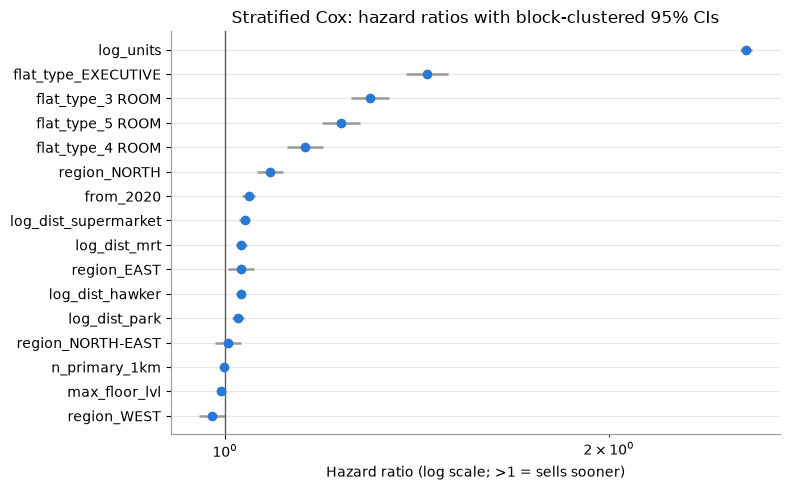

In [3]:
t1 = time.time()
cph_r = CoxPHFitter(penalizer=0.01).fit(Mf, "duration", "event", strata=["age_band"], cluster_col="address")
cph_n = CoxPHFitter(penalizer=0.01).fit(Mf.drop(columns="address"), "duration", "event", strata=["age_band"])
summ = cph_r.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].rename(
    columns={"exp(coef)": "HR", "exp(coef) lower 95%": "HR low", "exp(coef) upper 95%": "HR high"})
summ["SE ratio (robust / naive)"] = cph_r.summary["se(coef)"] / cph_n.summary["se(coef)"]
print(f"Fitted in {time.time() - t1:.0f}s · concordance {cph_r.concordance_index_:.3f} · partial log-likelihood {cph_r.log_likelihood_:,.0f}")
print(summ.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
o = summ.sort_values("HR")
ax.errorbar(o["HR"], range(len(o)), xerr=[o["HR"] - o["HR low"], o["HR high"] - o["HR"]], fmt="o", color=BLUE, ecolor=GREY)
ax.axvline(1, color="#5c5c57", lw=1); ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index); ax.set_xscale("log")
ax.set(xlabel="Hazard ratio (log scale; >1 = sells sooner)", title="Stratified Cox: hazard ratios with block-clustered 95% CIs")
plt.tight_layout(); plt.show()

**Finding:** Units of that flat type in the block dominate. The hazard ratio is 2.56 per log unit (95% CI 2.54–2.59), so doubling the units roughly doubles the sale rate.

- **Flat type** still matters after controlling for units: Executive 1.44 (1.39–1.50) and 3-room 1.30 (1.26–1.35), both against 2-room.
- **Location** effects are small. Each log-distance hazard ratio is 1.02–1.04, so blocks further from MRT, hawker centres, parks and supermarkets sell slightly *more* often: cheaper flats are more liquid. Primary schools have no effect (p = 0.32).
- **Standard errors:** the robust, block-clustered errors are 1.26–1.82 times the naive ones. Treating repeated spells in a block as independent would overstate precision by up to 45%. Every effect survives the wider intervals except the North-East and West region effects (p = 0.61 and 0.054).

## 3 · Does the final model satisfy proportional hazards?
Schoenfeld residual tests on a 30,000-spell sample (with 244,000 spells every tiny deviation is "significant", so the size of the
drift matters more than the p-value). Scaled Schoenfeld residuals plotted against time show the drift directly: a flat line means a constant effect.

                      test_statistic       p
max_floor_lvl                35.9208  0.0000
flat_type_4 ROOM             24.6447  0.0000
flat_type_5 ROOM             16.3228  0.0001
log_units                    15.2458  0.0001
flat_type_EXECUTIVE          15.2080  0.0001
log_dist_park                12.4109  0.0004
flat_type_3 ROOM             11.4438  0.0007
n_primary_1km                 7.3366  0.0068
log_dist_supermarket          3.7880  0.0516
log_dist_hawker               2.2045  0.1376
from_2020                     1.7346  0.1878
log_dist_mrt                  1.5927  0.2069
region_WEST                   1.5008  0.2205
region_EAST                   1.1068  0.2928
region_NORTH                  0.1168  0.7326
region_NORTH-EAST             0.0743  0.7852


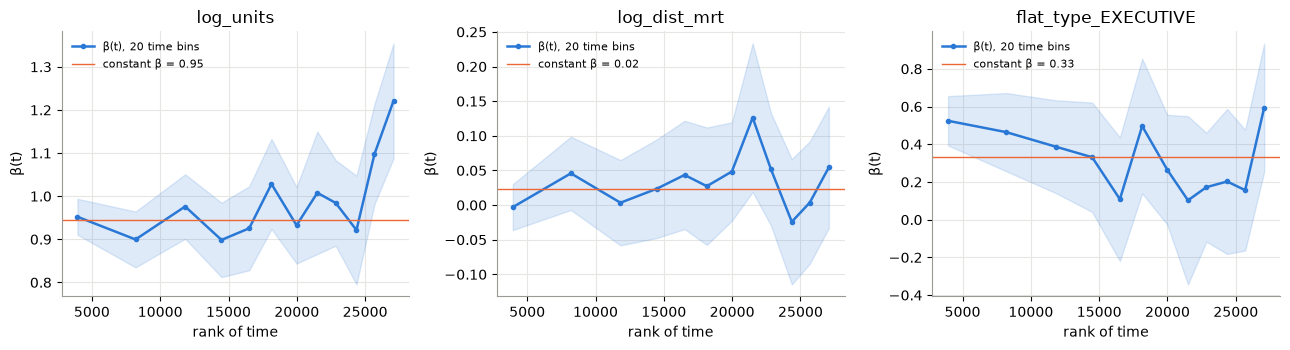

In [4]:
samp = Mf.drop(columns="address").sample(30000, random_state=0)
cph_s = CoxPHFitter(penalizer=0.01).fit(samp, "duration", "event", strata=["age_band"])
ph = proportional_hazard_test(cph_s, samp, time_transform="rank")
pht = ph.summary[["test_statistic", "p"]].sort_values("test_statistic", ascending=False)
print(pht.round(4).to_string())
ss = cph_s.compute_residuals(samp, "scaled_schoenfeld")
dur = samp.loc[ss.index, "duration"].rank()
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, c in zip(ax, ["log_units", "log_dist_mrt", "flat_type_EXECUTIVE"]):
    b0 = cph_s.params_[c]; y = ss[c] + b0                      # scaled Schoenfeld residual + β estimates β(t)
    bins = pd.qcut(dur, 20, duplicates="drop"); m = y.groupby(bins).mean(); se = y.groupby(bins).std() / np.sqrt(y.groupby(bins).size())
    xm = [iv.mid for iv in m.index]
    a.fill_between(xm, m - 1.96 * se, m + 1.96 * se, color=BLUE, alpha=0.15); a.plot(xm, m.values, color=BLUE, marker="o", ms=3, label="β(t), 20 time bins")
    a.axhline(b0, color=ORANGE, lw=1, label=f"constant β = {b0:.2f}"); a.set(title=f"{c}", xlabel="rank of time", ylabel="β(t)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Finding:** On the 30,000-spell sample, 8 of 16 covariates fail the PH test at 1%: block height (test statistic 36), the flat-type dummies (11–25), log units (15), park distance (12) and school count (7). MRT, hawker and supermarket distance, region and the post-2020 effect pass. With samples this large small drifts are flagged, so the plots matter more than the p-values:

- **Log units:** β(t) stays near 0.95 for most spells and rises only for the longest waits.
- **Executive:** the effect is strongest for short waits (about 0.5) and fades towards 0.2.

These drifts are modest next to the effects themselves. The model's job is to rank profiles and give expected waits, and §5 tests that directly. If needed, a time interaction for flat type is the refinement.

## 4 · Functional form and overall fit
**Martingale residuals** against each continuous covariate: a flat smoothed line means the covariate's form (log units, log distance) is adequate.
**Cox–Snell residuals**: if the model fits, they behave like a censored unit-exponential sample, so their Nelson–Aalen cumulative hazard follows the 45° line.

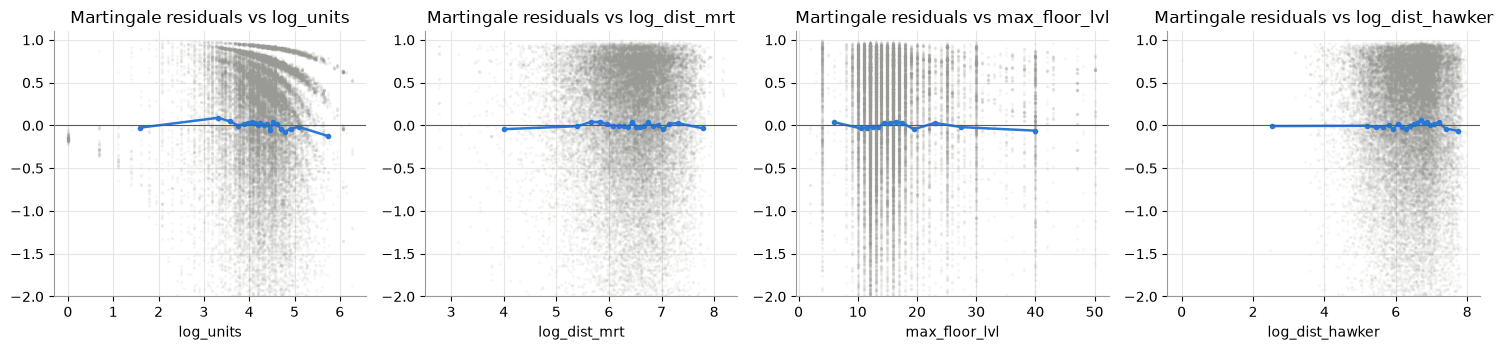

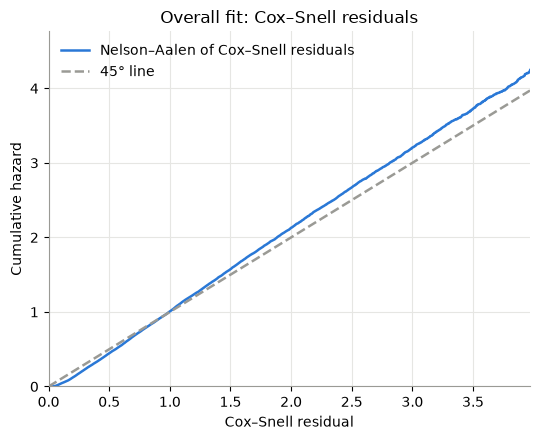

Mean |cumulative hazard − residual| up to the 90th percentile: 0.054


In [5]:
mres = cph_s.compute_residuals(samp, "martingale").reindex(samp.index)["martingale"]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, c in zip(ax, ["log_units", "log_dist_mrt", "max_floor_lvl", "log_dist_hawker"]):
    x = samp[c]; bins = pd.qcut(x, 20, duplicates="drop"); m = mres.groupby(bins).mean()
    a.scatter(x, mres, s=2, alpha=0.05, color=GREY); a.plot([iv.mid for iv in m.index], m.values, color=BLUE, marker="o", ms=3)
    a.axhline(0, color="#5c5c57", lw=0.8); a.set_ylim(-2, 1.1); a.set(title=f"Martingale residuals vs {c}", xlabel=c)
plt.tight_layout(); plt.show()
cs = samp["event"] - mres
na = NelsonAalenFitter().fit(cs, samp["event"])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
h = na.cumulative_hazard_
ax.plot(h.index, h.iloc[:, 0], color=BLUE, label="Nelson–Aalen of Cox–Snell residuals"); lim = np.quantile(cs, 0.99)
ax.plot([0, lim], [0, lim], "--", color=GREY, label="45° line"); ax.set(xlim=(0, lim), ylim=(0, lim * 1.2), xlabel="Cox–Snell residual",
       ylabel="Cumulative hazard", title="Overall fit: Cox–Snell residuals"); ax.legend()
plt.tight_layout(); plt.show()
q = h.index.to_series(); sel = q[q <= np.quantile(cs, 0.9)]
print(f"Mean |cumulative hazard − residual| up to the 90th percentile: {np.mean(np.abs(h.loc[sel.index].iloc[:, 0] - sel)):.3f}")

**Finding:** The martingale residuals are flat across log units, log MRT distance, block height and log hawker distance, apart from a slight dip at the very largest blocks. The log transforms are therefore adequate.

The Cox–Snell residuals track the 45° line closely up to a cumulative hazard of about 1 and drift slightly above it in the far tail (mean gap 0.054 up to the 90th percentile). Overall fit is good; the small departure concerns only the longest spells.

## 5 · Is Cox the right model? Five candidates on the same time split
Train on spells starting before 2023, test on spells starting 2023 or later (scored on a 20,000-spell test sample):

- **Kaplan–Meier by flat type** (no covariates beyond flat type)
- **Stratified Cox** (production)
- **Weibull AFT** and **log-normal AFT** (parametric; Weibull allows a hazard that rises or falls with time)
- **Random survival forest** (machine learning; trained on a 25,000-spell sample)

Metrics: Harrell's C-index on predicted survival at 12 months (bootstrap 95% CI), integrated Brier score over 1–24 months
(IPCW-weighted; lower is better; 0.25 = coin-flip), and calibration at 12 months.

In [6]:
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import integrated_brier_score
from sksurv.util import Surv
tr_m = (F["start_year"] < 2023).to_numpy()
Tr, Te = Mf[tr_m].drop(columns="address"), Mf[~tr_m].drop(columns="address")
te = Te.sample(20000, random_state=1); Fte = F.loc[te.index]
grid = np.arange(1, 25)
pred = {}
t1 = time.time()
km_by = {t: KaplanMeierFitter().fit(F.loc[tr_m & (F["flat_type"] == t).to_numpy(), "duration"], F.loc[tr_m & (F["flat_type"] == t).to_numpy(), "event"]) for t in K.TYPES}
pred["Kaplan–Meier by flat type"] = np.vstack([km_by[t].survival_function_at_times(grid).to_numpy() for t in Fte["flat_type"]])
cox = CoxPHFitter(penalizer=0.01).fit(Tr, "duration", "event", strata=["age_band"])
pred["Stratified Cox"] = cox.predict_survival_function(te, times=grid).loc[:, te.index].to_numpy().T   # stratified output is grouped by stratum: realign
age_d = lambda D: pd.get_dummies(D["age_band"], prefix="age", drop_first=True, dtype=float).reindex(columns=[f"age_{a}" for a in S.AGE_LABELS[1:]], fill_value=0.0)
TrA, teA = pd.concat([Tr.drop(columns="age_band"), age_d(Tr)], axis=1), pd.concat([te.drop(columns="age_band"), age_d(te)], axis=1)
wb = WeibullAFTFitter(penalizer=0.01).fit(TrA, "duration", "event")
pred["Weibull AFT"] = wb.predict_survival_function(teA, times=grid).to_numpy().T
ln = LogNormalAFTFitter(penalizer=0.01).fit(TrA, "duration", "event")
pred["Log-normal AFT"] = ln.predict_survival_function(teA, times=grid).to_numpy().T
rs_tr = TrA.sample(25000, random_state=2)
Xcols = [c for c in TrA.columns if c not in ("duration", "event")]
rsf = RandomSurvivalForest(n_estimators=150, min_samples_leaf=40, max_features="sqrt", n_jobs=2, random_state=0)
rsf.fit(rs_tr[Xcols].to_numpy(), Surv.from_arrays(rs_tr["event"].astype(bool), rs_tr["duration"]))
sf = rsf.predict_survival_function(teA[Xcols].to_numpy())
pred["Random survival forest"] = np.vstack([f(grid) for f in sf])
print(f"Five models fitted and scored in {time.time() - t1:.0f}s · Weibull shape ρ = {np.exp(wb.params_.loc['rho_', 'Intercept']):.2f}")

y_tr = Surv.from_arrays(Tr["event"].astype(bool), Tr["duration"]); y_te = Surv.from_arrays(te["event"].astype(bool), te["duration"])
rng = np.random.default_rng(0); idx12 = list(grid).index(12)
rows = []
for name, P in pred.items():
    s12 = P[:, idx12]
    c = concordance_index(te["duration"], s12, te["event"])
    boots = [concordance_index(te["duration"].to_numpy()[b], s12[b], te["event"].to_numpy()[b]) for b in (rng.integers(0, len(te), len(te)) for _ in range(100))]
    ibs = integrated_brier_score(y_tr, y_te, np.clip(P, 0, 1), grid)
    rows.append({"model": name, "C-index": c, "95% CI": f"{np.percentile(boots, 2.5):.3f}–{np.percentile(boots, 97.5):.3f}", "Integrated Brier (1–24m)": ibs,
                 "Predicted P(sale by 12m)": 1 - s12.mean()})
km_all = KaplanMeierFitter().fit(te["duration"], te["event"])
comp = pd.DataFrame(rows).set_index("model")
comp["Observed P(sale by 12m), KM"] = 1 - km_all.survival_function_at_times(12).iloc[0]
print(comp.round(4).to_string())

Five models fitted and scored in 72s · Weibull shape ρ = 0.97


                           C-index       95% CI  Integrated Brier (1–24m)  Predicted P(sale by 12m)  Observed P(sale by 12m), KM
model                                                                                                                           
Kaplan–Meier by flat type   0.5499  0.545–0.554                    0.1132                    0.8280                       0.8362
Stratified Cox              0.6777  0.673–0.682                    0.0955                    0.8333                       0.8362
Weibull AFT                 0.6538  0.649–0.658                    0.0997                    0.8397                       0.8362
Log-normal AFT              0.6551  0.650–0.660                    0.0989                    0.8492                       0.8362
Random survival forest      0.6544  0.650–0.659                    0.0985                    0.8464                       0.8362


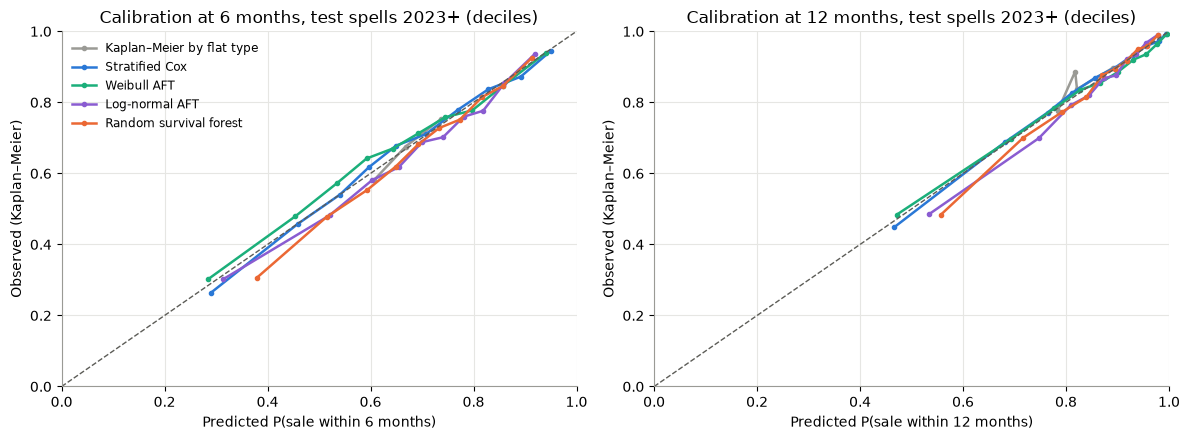

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for h, a in zip([6, 12], axs):
    k = list(grid).index(h)
    for (name, P), c in zip(pred.items(), [GREY, BLUE, GREEN, "#8a5cd1", ORANGE]):
        p_ev = 1 - P[:, k]; dec = pd.qcut(p_ev, 10, labels=False, duplicates="drop")
        obs = [1 - KaplanMeierFitter().fit(te["duration"].to_numpy()[dec == q], te["event"].to_numpy()[dec == q]).survival_function_at_times(h).iloc[0] for q in np.unique(dec)]
        prd = [p_ev[dec == q].mean() for q in np.unique(dec)]
        a.plot(prd, obs, marker="o", ms=3, color=c, label=name)
    a.plot([0, 1], [0, 1], "--", color="#5c5c57", lw=1); a.set(xlim=(0, 1), ylim=(0, 1), xlabel=f"Predicted P(sale within {h} months)",
          ylabel="Observed (Kaplan–Meier)", title=f"Calibration at {h} months, test spells 2023+ (deciles)")
axs[0].legend(fontsize=8.5); plt.tight_layout(); plt.show()

**Finding:** The stratified Cox model has the best ranking and the lowest Brier score of the five:

| Model | C-index (95% CI) | Integrated Brier score |
|---|---|---|
| Stratified Cox | 0.678 (0.673–0.682) | 0.0955 |
| Weibull AFT, log-normal AFT, random survival forest | 0.653–0.655 | 0.099–0.100 |
| Kaplan–Meier by flat type | 0.550 | 0.113 |

The confidence intervals don't overlap, so Cox's advantage is real. Every model is well calibrated, both in aggregate (predicted 12-month sale probability 0.83–0.85 against 0.836 observed) and across deciles at 6 and 12 months.

The Weibull shape is 0.97, a nearly constant hazard, so a flexible parametric baseline adds nothing. Cox's separate baselines for each block-age band capture what a single shape cannot. The random survival forest, despite its flexibility, does not beat Cox. It was trained on a 25,000-spell sample, so this is a fair but not exhaustive comparison.

## 6 · Sensitivity of the design choices
**Left truncation.** For blocks resellable before 2017, the spell before their first observed sale is dropped (its start is unknown). If that
biased the model, hazard ratios fitted on newer blocks only (whose spells all start at MOP, fully observed) would differ.

**Market activity.** The production model uses a crude post-2020 indicator. Here it is replaced by the national resale rate in the
12 months before each spell starts (resales per 100 flats), and compared on the same time split.

In [8]:
newer = (F["year_completed"] + 5 >= 2017).to_numpy()
cph_new = CoxPHFitter(penalizer=0.01).fit(Mf[newer].drop(columns="address"), "duration", "event", strata=["age_band"])
lt = pd.DataFrame({"All blocks HR": np.exp(cph_n.params_), "Newer blocks only HR": np.exp(cph_new.params_)}).dropna()
lt["Ratio"] = lt["Newer blocks only HR"] / lt["All blocks HR"]
print(f"Newer blocks: {newer.sum():,} spells ({newer.mean():.0%})")
print(lt.round(3).to_string())

Newer blocks: 55,880 spells (23%)
                      All blocks HR  Newer blocks only HR  Ratio
covariate                                                       
flat_type_3 ROOM              1.300                 1.419  1.092
flat_type_4 ROOM              1.155                 1.590  1.376
flat_type_5 ROOM              1.233                 1.516  1.230
flat_type_EXECUTIVE           1.441                 0.092  0.064
region_EAST                   1.029                 0.968  0.941
region_NORTH                  1.085                 0.844  0.778
region_NORTH-EAST             1.006                 0.909  0.904
region_WEST                   0.977                 0.855  0.875
log_dist_mrt                  1.030                 0.990  0.961
log_dist_hawker               1.029                 1.032  1.003
log_dist_park                 1.024                 1.027  1.003
log_dist_supermarket          1.037                 1.074  1.036
log_units                     2.563                 2.21

In [9]:
sales_m = K.sales(); sales_m = sales_m[sales_m["in_scope"]].groupby("t").size()
stock_units = K.stock()["units"].sum()
mk = (sales_m.rolling(12, min_periods=6).sum() / stock_units * 100).rename("market_rate")
Fm = Mf.drop(columns="address").copy()
Fm["market_rate"] = F["t_start"].map(lambda t: mk.get(t - 1, np.nan)).to_numpy()
Fm["market_rate"] = Fm["market_rate"].fillna(Fm["market_rate"].median())
res = []
for name, cols in [("Post-2020 indicator (production)", [c for c in Fm.columns if c != "market_rate"]),
                   ("Market resale rate at spell start", [c for c in Fm.columns if c != "from_2020"])]:
    m = CoxPHFitter(penalizer=0.01).fit(Fm.loc[tr_m, cols], "duration", "event", strata=["age_band"])
    tt = Fm.loc[te.index, cols]
    c = concordance_index(tt["duration"], m.predict_expectation(tt), tt["event"])
    res.append({"variant": name, "train partial AIC": m.AIC_partial_, "test C-index": c})
print(pd.DataFrame(res).set_index("variant").round(3).to_string())
print(f"Market rate range: {mk.min():.2f}–{mk.max():.2f} resales per 100 flats a year")

                                   train partial AIC  test C-index
variant                                                           
Post-2020 indicator (production)         2741595.702         0.678
Market resale rate at spell start        2741851.848         0.677
Market rate range: 0.97–2.89 resales per 100 flats a year


**Finding:**

- **Left truncation:** on newer blocks only (23% of spells, all observed from MOP), the size and location effects are close to the full model: log units 2.21 against 2.56, and distance hazard ratios within 4%. The differences appear where newer blocks have little variation. Almost no Executive flats were built after 2012, so that estimate (0.09) is unstable; region effects shift; and the post-2020 effect is 0.75, because in newer blocks early spells start right at MOP, when turnover peaks. The core conclusions do not depend on how truncated spells are handled.
- **Market activity:** replacing the post-2020 indicator with the market resale rate at spell start leaves the test C-index unchanged (0.677 against 0.678) and worsens AIC, so the simpler indicator stays.

## 7 · Rolling backtest of the production availability estimate, 2019–2025
At each as-of date (June each year) the full production chain re-runs on data up to then: profiles, Cox fit, flat-type calibration, blend
with recent sales. Predictions of sales in the next 12 months are scored against what happened. The blend weight (prior strength, in years of
observed sales) is varied to show the chosen 0.25 is not a lucky pick from one date.

In [10]:
def next12(as_of, rows):
    t_end = K.month_index(as_of)
    key = rows.set_index(["address", "flat_type", "storey_band"])["profile_id"]
    s = K.sales(); s = s[s["in_scope"] & (s["t"] > t_end) & (s["t"] <= t_end + 12)].drop(columns="profile_id")
    s = s.assign(storey_band=K.band(s["storey_mid"], C.STOREY_BANDS)).join(key, on=["address", "flat_type", "storey_band"], how="inner")
    return s.groupby("profile_id").size()

ALPHAS = [0, 0.1, 0.25, 0.5, 1, 2, 5]
records, cover = [], []
t1 = time.time()
for as_of in ["2019-06", "2020-06", "2021-06", "2022-06", "2023-06", "2024-06", "2025-06"]:
    cph_b = S.fit(as_of)
    _, d = S.profile_waits(cph_b, as_of)
    rows = PR.profile_rows(as_of)
    d = d.set_index("profile_id"); d["actual"] = next12(as_of, rows).reindex(d.index).fillna(0)
    for a in ALPHAS:
        p = (d["sales_last12"] + a * d["model_calibrated"]) / (1 + a)
        records.append({"as_of": as_of, "method": f"blend α={a}", "spearman": spearmanr(p, d["actual"]).correlation,
                        "MAE": (p - d["actual"]).abs().mean(), "total_err": p.sum() / d["actual"].sum() - 1,
                        "P(>=1) pred": (1 - np.exp(-p)).mean(), "P(>=1) obs": (d["actual"] > 0).mean()})
    for name, p in [("Cox model only (calibrated)", d["model_calibrated"]), ("Cox model only (raw)", d["model_per_year"])]:
        records.append({"as_of": as_of, "method": name, "spearman": spearmanr(p, d["actual"]).correlation, "MAE": (p - d["actual"]).abs().mean(),
                        "total_err": p.sum() / d["actual"].sum() - 1, "P(>=1) pred": (1 - np.exp(-p)).mean(), "P(>=1) obs": (d["actual"] > 0).mean()})
    a = S.PRIOR_YEARS; r_ = a * d["model_calibrated"] + d["sales_last12"]
    lo, hi = nbinom.ppf(0.1, r_.clip(lower=1e-9), (1 + a) / (2 + a)), nbinom.ppf(0.9, r_.clip(lower=1e-9), (1 + a) / (2 + a))
    pois_lo, pois_hi = poisson.ppf(0.1, r_ / (1 + a)), poisson.ppf(0.9, r_ / (1 + a))
    cover.append({"as_of": as_of, "profiles": len(d), "80% interval coverage (Poisson–gamma)": ((d["actual"] >= lo) & (d["actual"] <= hi)).mean(),
                  "80% coverage if rate were known (Poisson)": ((d["actual"] >= pois_lo) & (d["actual"] <= pois_hi)).mean()})
    print(f"{as_of}: {len(d):,} profiles · {time.time() - t1:.0f}s")
bt = pd.DataFrame(records)
summary = bt.groupby("method")[["spearman", "MAE", "total_err"]].agg(["mean", "min", "max"])
order = ["Cox model only (raw)", "Cox model only (calibrated)"] + [f"blend α={a}" for a in ALPHAS]
print(summary.reindex(order).round(3).to_string())

2019-06: 1,669 profiles · 9s


2020-06: 1,687 profiles · 16s


2021-06: 1,733 profiles · 24s


2022-06: 1,814 profiles · 32s


2023-06: 1,865 profiles · 39s


2024-06: 1,862 profiles · 48s


2025-06: 1,826 profiles · 58s
                            spearman                  MAE                total_err              
                                mean    min    max   mean    min     max      mean    min    max
method                                                                                          
Cox model only (raw)           0.742  0.676  0.772  9.451  7.017  10.250    -0.035 -0.509  0.194
Cox model only (calibrated)    0.819  0.766  0.846  7.677  7.155   8.890     0.078 -0.170  0.279
blend α=0                      0.901  0.853  0.923  4.554  3.987   5.108     0.078 -0.170  0.279
blend α=0.1                    0.905  0.857  0.926  4.468  3.880   5.103     0.078 -0.170  0.279
blend α=0.25                   0.905  0.856  0.926  4.473  3.897   5.156     0.078 -0.170  0.279
blend α=0.5                    0.902  0.852  0.922  4.653  4.083   5.355     0.078 -0.170  0.279
blend α=1                      0.892  0.841  0.914  5.120  4.585   5.762     0.078 -0.170  0.279


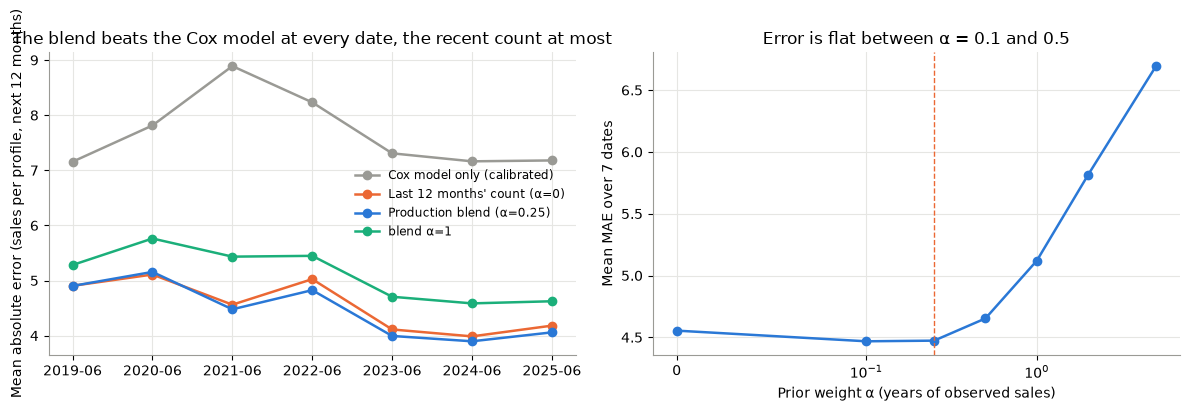

         spearman    MAE  total_err  P(>=1) pred  P(>=1) obs
as_of                                                       
2019-06     0.856  4.902      0.279        0.826       0.799
2020-06     0.899  5.156     -0.170        0.812       0.834
2021-06     0.912  4.478      0.086        0.844       0.832
2022-06     0.904  4.825      0.139        0.824       0.805
2023-06     0.916  3.994      0.044        0.815       0.799
2024-06     0.924  3.897      0.012        0.827       0.817
2025-06     0.926  4.059      0.155        0.838       0.827


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
piv = bt.pivot(index="as_of", columns="method", values="MAE")
for m, c in [("Cox model only (calibrated)", GREY), ("blend α=0", ORANGE), ("blend α=0.25", BLUE), ("blend α=1", GREEN)]:
    ax[0].plot(piv.index, piv[m], marker="o", color=c, label={"blend α=0": "Last 12 months' count (α=0)", "blend α=0.25": "Production blend (α=0.25)"}.get(m, m))
ax[0].set(ylabel="Mean absolute error (sales per profile, next 12 months)", title="The blend beats the Cox model at every date, the recent count at most"); ax[0].legend(fontsize=8.5)
mean_mae = bt[bt["method"].str.startswith("blend")].groupby("method")["MAE"].mean()
xs = [float(m.split("=")[1]) for m in mean_mae.index]
ax[1].plot(xs, mean_mae.values, marker="o", color=BLUE); ax[1].set_xscale("symlog", linthresh=0.1)
ax[1].axvline(S.PRIOR_YEARS, color=ORANGE, ls="--", lw=1); ax[1].set(xlabel="Prior weight α (years of observed sales)", ylabel="Mean MAE over 7 dates", title="Error is flat between α = 0.1 and 0.5")
plt.tight_layout(); plt.show()
prod = bt[bt["method"] == f"blend α={S.PRIOR_YEARS}"].set_index("as_of")[["spearman", "MAE", "total_err", "P(>=1) pred", "P(>=1) obs"]]
print(prod.round(3).to_string())

**Finding:** The blend with α = 0.25 outperforms both its inputs across the 7 as-of dates:

| Method | Spearman (mean) | MAE, sales per profile (mean) |
|---|---|---|
| Blend, α = 0.25 | 0.905 | 4.47 |
| Recent count alone | 0.901 | 4.55 |
| Calibrated Cox model alone | 0.819 | 7.68 |

It beats the Cox model at every date and the recent count at 5 of 7 (tied in 2019, slightly worse in 2020). Error is flat for α between 0.1 and 0.25 and rises steadily beyond 0.5. The chosen weight sits in a broad optimum, not on a knife-edge from one date. Predicted P(at least one sale in 12 months) is within 0.03 of observed at every date.

The total volume error swings with the market: +28% for Jun 2019, whose next year included the 2020 lockdown, and −17% for Jun 2020, ahead of the 2021 boom. Calibration assumes the next 12 months resemble the last 12; removing the swing would need a volume forecast.

## 8 · How uncertain is each profile's wait?
The blend is a Poisson–gamma (empirical Bayes) model: the profile's yearly sale rate has a gamma posterior with shape = sales in the last
12 months + α × calibrated model rate, and rate = 1 + α. That gives an interval for the rate, hence for the wait, and a predictive
(negative binomial) interval for next year's sales, whose coverage can be checked against the backtest.

In [12]:
cv = pd.DataFrame(cover).set_index("as_of")
print(cv.round(3).to_string())
wnow, dnow = S.profile_waits(S.fit(AS_OF), AS_OF)
dnow = dnow.merge(wnow[["profile_id", "wait_months"]], on="profile_id")          # detail already carries wait_p10 / wait_p90
ex = dnow.sort_values("sales_last12", ascending=False)
pick = pd.concat([ex.head(2), ex.iloc[[len(ex) // 2]], ex[ex["sales_last12"] == 1].head(1), ex[ex["sales_last12"] == 0].head(1)])
print(pick[["profile_id", "sales_last12", "model_calibrated", "wait_months", "wait_p10", "wait_p90"]].round(2).to_string(index=False))
print(f"Median 80% interval width: {(dnow['wait_p90'] - dnow['wait_p10']).median():.1f} months; profiles with an upper bound at the 120-month cap: {(dnow['wait_p90'] >= 120).mean():.1%}")

         profiles  80% interval coverage (Poisson–gamma)  80% coverage if rate were known (Poisson)
as_of                                                                                              
2019-06      1669                                  0.726                                      0.626
2020-06      1687                                  0.748                                      0.667
2021-06      1733                                  0.778                                      0.685
2022-06      1814                                  0.761                                      0.670
2023-06      1865                                  0.802                                      0.722
2024-06      1862                                  0.824                                      0.726
2025-06      1826                                  0.797                                      0.697


                          profile_id  sales_last12  model_calibrated  wait_months  wait_p10  wait_p90
WOODLANDS|4 ROOM|60-79|500m-1km|7-12         151.0            116.19         0.08      0.08      0.09
        SENGKANG|4 ROOM|80+|>1km|13+         151.0             78.56         0.09      0.08      0.10
   WOODLANDS|3 ROOM|80+|500m-1km|13+           6.0              8.84         1.83      1.25      3.11
     JURONG EAST|5 ROOM|80+|>1km|1-6           1.0              0.89        12.27      5.60     83.26
      YISHUN|EXECUTIVE|<60|>1km|7-12           0.0              0.24       120.00    120.00    120.00
Median 80% interval width: 1.6 months; profiles with an upper bound at the 120-month cap: 14.8%


**Finding:** The 80% predictive intervals cover 73–82% of profiles' next-year sales: 78% on average and 80–82% for 2023–2025. If the rate were treated as known, coverage would be only 63–73%, so accounting for uncertainty in the rate is what makes the intervals honest. The shortfalls coincide with the 2019–2022 market shocks.

Production now publishes `wait_p10` and `wait_p90` in `expected_wait.csv`. Today the median 80% interval is about 1.6 months wide, and about 15% of profiles have an upper bound at the 120-month cap (the scarce ones).

## 9 · Summary

**Finding:** The availability model passes the checks a survival analyst would run, and where a check flags a weakness, the production design already handles it:

| Check | Result | Consequence |
|---|---|---|
| PH by block age (log–log plots) | Violated: curves cross | Block age is a stratum |
| PH in the final model (Schoenfeld) | Modest drift for flat type, units, block height | Effects read as averages over the wait; ranking tested directly in §5 |
| Functional form (martingale) | Flat | Log units and log distances kept |
| Overall fit (Cox–Snell) | On the 45° line up to ~1 | Good fit |
| Repeated spells | Robust SEs 1.3–1.8× naive | Block-clustered SEs reported |
| Model choice | Cox C = 0.678, best of 5; best Brier score | Cox kept over AFT and the random survival forest |
| Calibration | Within ±0.03 at 6 and 12 months | Probabilities usable as published |
| Left truncation | Core effects stable | Design kept |
| Rolling backtest, 7 dates | Blend best overall; α robust | α = 0.25 kept |
| Interval coverage | 78% for an 80% target | Intervals published |